# 01 · Data preparation (Methods 3.1)
Clean → remove PII → balance → 70/30 split → encode. Every count below is also checked by `pytest`.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


## Row counts at every step

In [2]:
s = data.summary()
display(pd.Series(s, name="value").to_frame())
assert s["clean_rows"] == 7032 and s["pii_columns_left"] == []
assert s["balanced_rows"] == 3738 and (s["train_rows"], s["val_rows"]) == (2616, 1122)

,value
raw_rows,7043
clean_rows,7032
dropped_blank_totalcharges,11
pii_columns_left,[]
churn_after_clean,1869
balanced_rows,3738
balanced_churn,1869
train_rows,2616
val_rows,1122
train_churn_share,0.5


**PII:** `customerID` is the only direct identifier and is dropped in `data.clean`; no names, phone numbers or addresses exist (Methods 3.1.2).

## Class balance before and after downsampling

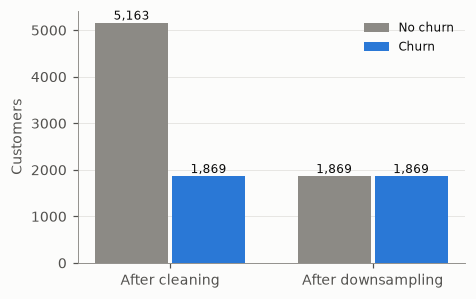

In [3]:
fig = plots.fig_class_balance(s)
plots.save(fig, FIGS, "nb01_class_balance")

## Encoded features (fitted on the training rows only)

In [4]:
for m in config.MODELS:
    d = data.prepare(m)
    print(f"{m:>3}: train {d.X_train.shape}, val {d.X_val.shape}, scaled={m == 'svm'}")
print(d.feature_names[:8], "...")

svm: train (2616, 45), val (1122, 45), scaled=True
 rf: train (2616, 45), val (1122, 45), scaled=False
xgb: train (2616, 45), val (1122, 45), scaled=False
['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes'] ...
